# VisNet / DPN — Chest X-ray Denoising (JSRT)

Replication of **VisNet: A Human Visual System Inspired Lightweight Dual-Path Network for Medical Images Denoising** (MICCAI 2025).


In [ ]:
# Cell 1: Setup
!pip install -q kaggle scikit-image

import os, random, glob
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as sk_psnr
from skimage.metrics import structural_similarity as sk_ssim

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
seed_everything(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cpu":
    print("No GPU — go to Runtime > Change runtime type > T4 GPU for reasonable speed.")


Device: cuda


## 1. Data: Download & Build Noisy/Clean Pairs

Downloads JSRT from Kaggle, splits 197 train / 50 val, resizes to a fixed size, and generates AWGN-noisy counterparts.

In [ ]:
# Cell 2: Kaggle download + GT/NOISY pair generation
KAGGLE_JSON = Path.home() / ".kaggle" / "kaggle.json"
KAGGLE_JSON.parent.mkdir(parents=True, exist_ok=True)

if not KAGGLE_JSON.exists():
    from google.colab import files
    print("Upload kaggle.json (Kaggle > Account > Create New API Token)")
    uploaded = files.upload()
    for fname in uploaded:
        Path(fname).rename(KAGGLE_JSON)
os.chmod(KAGGLE_JSON, 0o600)

RAW_DIR = Path("/content/data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)
if not any(RAW_DIR.iterdir()):
    os.system(f"kaggle datasets download -d raddar/nodules-in-chest-xrays-jsrt -p {RAW_DIR} --unzip")

# Recursive search handles whatever folder layout / format Kaggle gives us
exts = (".dcm", ".png", ".jpg", ".jpeg", ".bmp")
all_files = sorted(p for p in RAW_DIR.rglob("*") if p.suffix.lower() in exts)
print(f"Found {len(all_files)} source images")
assert len(all_files) > 0, "No images found — check the Kaggle download."

IMG_SIZE = 256          # resize target
SIGMA = 25 / 255.0       # AWGN noise level

def load_rgb(path):
    '''Load any format as (H, W, 3) uint8 RGB. Grayscale sources get channel-duplicated.'''
    if path.suffix.lower() == ".dcm":
        import pydicom
        arr = pydicom.dcmread(str(path)).pixel_array.astype(np.float32)
        arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)
        arr = (arr * 255).astype(np.uint8)
        return np.stack([arr] * 3, axis=-1) if arr.ndim == 2 else arr
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    return img[:, :, ::-1]

base = Path("/content/data")
train_dir, val_dir = base / "train", base / "val"
for d in [train_dir / "gt", train_dir / "noisy", val_dir / "gt", val_dir / "noisy"]:
    d.mkdir(parents=True, exist_ok=True)

random.Random(42).shuffle(all_files)
train_files, val_files = all_files[:197], all_files[197:247]
print(f"Train: {len(train_files)} | Val: {len(val_files)}")

def build_pairs(files, gt_dir, noisy_dir):
    for f in files:
        img = cv2.resize(load_rgb(f), (IMG_SIZE, IMG_SIZE)).astype(np.float32) / 255.0
        noisy = np.clip(img + np.random.normal(0, SIGMA, img.shape), 0, 1)
        name = f.stem + ".png"
        cv2.imwrite(str(gt_dir / name), (img * 255).astype(np.uint8)[:, :, ::-1])
        cv2.imwrite(str(noisy_dir / name), (noisy * 255).astype(np.uint8)[:, :, ::-1])

if not any((train_dir / "gt").iterdir()):
    build_pairs(train_files, train_dir / "gt", train_dir / "noisy")
    build_pairs(val_files, val_dir / "gt", val_dir / "noisy")
print("Pairs ready:", len(list((train_dir/'gt').glob('*.png'))), "train,",
      len(list((val_dir/'gt').glob('*.png'))), "val")


Upload kaggle.json (Kaggle > Account > Create New API Token)


Saving kaggle.json to kaggle.json
Found 247 source images
Train: 197 | Val: 50
Pairs ready: 197 train, 50 val


## 2. Dataset & DataLoader

Random crop + flip/transpose augmentation (cheap, helps a lot on a 247-image dataset).

In [ ]:
# Cell 3: Dataset
class JSRTDataset(Dataset):
    def __init__(self, gt_dir, noisy_dir, patch_size=128, train=True):
        self.gt_dir, self.noisy_dir = Path(gt_dir), Path(noisy_dir)
        self.files = sorted(p.name for p in self.gt_dir.glob("*.png"))
        self.patch_size = patch_size
        self.train = train

    def __len__(self):
        return len(self.files)

    def _augment(self, a, b):
        if random.random() < 0.5: a, b = np.flip(a, 1), np.flip(b, 1)
        if random.random() < 0.5: a, b = np.flip(a, 0), np.flip(b, 0)
        if random.random() < 0.5: a, b = np.transpose(a, (1, 0, 2)), np.transpose(b, (1, 0, 2))
        return np.ascontiguousarray(a), np.ascontiguousarray(b)

    def __getitem__(self, idx):
        name = self.files[idx]
        gt = cv2.imread(str(self.gt_dir / name))[:, :, ::-1] / 255.0
        noisy = cv2.imread(str(self.noisy_dir / name))[:, :, ::-1] / 255.0
        gt, noisy = gt.astype(np.float32), noisy.astype(np.float32)

        if self.train:
            h, w, _ = gt.shape
            ps = min(self.patch_size, h, w)
            y, x = random.randint(0, h - ps), random.randint(0, w - ps)
            gt, noisy = gt[y:y+ps, x:x+ps], noisy[y:y+ps, x:x+ps]
            noisy, gt = self._augment(noisy, gt)

        return (torch.from_numpy(noisy.transpose(2, 0, 1)).float(),
                torch.from_numpy(gt.transpose(2, 0, 1)).float())


PATCH_SIZE = 128   # lower memory footprint for free-tier Colab; use 256 to match the repo default
BATCH_SIZE = 2

train_dataset = JSRTDataset(train_dir/"gt", train_dir/"noisy", PATCH_SIZE, train=True)
val_dataset = JSRTDataset(val_dir/"gt", val_dir/"noisy", PATCH_SIZE, train=False)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=1, shuffle=False, num_workers=2)
print(f"Train batches: {len(train_loader)} | Val samples: {len(val_dataset)}")


Train batches: 98 | Val samples: 50


## 3. Model — DPN / VisNet

Dual-path (magno/parvo) + shared deformable-conv edge-shape stage + spatial-semantic fusion. 3-channel in/out, ~0.15M params.

In [ ]:
# Cell 4: Deformable convolution
class DeformConv2d(nn.Module):
    def __init__(self, inc, outc, kernel_size=3, padding=1, stride=1):
        super().__init__()
        self.kernel_size, self.padding, self.stride = kernel_size, padding, stride
        self.zero_padding = nn.ZeroPad2d(padding)
        self.conv = nn.Conv2d(inc, outc, kernel_size=kernel_size, stride=kernel_size)
        self.p_conv = nn.Conv2d(inc, 2 * kernel_size * kernel_size, 3, padding=1, stride=stride)
        nn.init.constant_(self.p_conv.weight, 0)
        self.p_conv.register_full_backward_hook(self._set_lr)

    @staticmethod
    def _set_lr(module, grad_input, grad_output):
        # Scale offset-conv gradients by 0.1x (standard DCNv2 stabilization trick)
        return tuple(g * 0.1 if g is not None else None for g in grad_input)

    def forward(self, x):
        offset = self.p_conv(x)
        dtype = offset.data.type()
        ks, N = self.kernel_size, offset.size(1) // 2
        if self.padding: x = self.zero_padding(x)

        p = self._get_p(offset, dtype).contiguous().permute(0, 2, 3, 1)
        q_lt = p.detach().floor()
        q_rb = q_lt + 1
        q_lt = torch.cat([torch.clamp(q_lt[..., :N], 0, x.size(2)-1),
                           torch.clamp(q_lt[..., N:], 0, x.size(3)-1)], -1).long()
        q_rb = torch.cat([torch.clamp(q_rb[..., :N], 0, x.size(2)-1),
                           torch.clamp(q_rb[..., N:], 0, x.size(3)-1)], -1).long()
        q_lb = torch.cat([q_lt[..., :N], q_rb[..., N:]], -1)
        q_rt = torch.cat([q_rb[..., :N], q_lt[..., N:]], -1)
        p = torch.cat([torch.clamp(p[..., :N], 0, x.size(2)-1),
                        torch.clamp(p[..., N:], 0, x.size(3)-1)], -1)

        g_lt = (1+(q_lt[...,:N].type_as(p)-p[...,:N]))*(1+(q_lt[...,N:].type_as(p)-p[...,N:]))
        g_rb = (1-(q_rb[...,:N].type_as(p)-p[...,:N]))*(1-(q_rb[...,N:].type_as(p)-p[...,N:]))
        g_lb = (1+(q_lb[...,:N].type_as(p)-p[...,:N]))*(1-(q_lb[...,N:].type_as(p)-p[...,N:]))
        g_rt = (1-(q_rt[...,:N].type_as(p)-p[...,:N]))*(1+(q_rt[...,N:].type_as(p)-p[...,N:]))

        x_offset = (g_lt.unsqueeze(1)*self._get_x_q(x,q_lt,N) + g_rb.unsqueeze(1)*self._get_x_q(x,q_rb,N) +
                    g_lb.unsqueeze(1)*self._get_x_q(x,q_lb,N) + g_rt.unsqueeze(1)*self._get_x_q(x,q_rt,N))
        return self.conv(self._reshape_x_offset(x_offset, ks))

    def _get_p_n(self, N, dtype):
        k = self.kernel_size
        y, x = torch.meshgrid(torch.arange(-(k-1)//2,(k-1)//2+1), torch.arange(-(k-1)//2,(k-1)//2+1), indexing='ij')
        return torch.cat([torch.flatten(y), torch.flatten(x)], 0).view(1,2*N,1,1).type(dtype)

    def _get_p_0(self, h, w, N, dtype):
        y, x = torch.meshgrid(torch.arange(1,h*self.stride+1,self.stride), torch.arange(1,w*self.stride+1,self.stride), indexing='ij')
        y = torch.flatten(y).view(1,1,h,w).repeat(1,N,1,1)
        x = torch.flatten(x).view(1,1,h,w).repeat(1,N,1,1)
        return torch.cat([y, x], 1).type(dtype)

    def _get_p(self, offset, dtype):
        N, h, w = offset.size(1)//2, offset.size(2), offset.size(3)
        return self._get_p_0(h,w,N,dtype) + self._get_p_n(N,dtype) + offset

    def _get_x_q(self, x, q, N):
        b, h, w, _ = q.size()
        c, pw = x.size(1), x.size(3)
        x = x.contiguous().view(b, c, -1)
        idx = (q[...,:N]*pw + q[...,N:]).unsqueeze(1).expand(-1,c,-1,-1,-1).contiguous().view(b,c,-1)
        return x.gather(-1, idx).contiguous().view(b, c, h, w, N)

    @staticmethod
    def _reshape_x_offset(x_offset, ks):
        b, c, h, w, N = x_offset.size()
        x_offset = torch.cat([x_offset[...,s:s+ks].contiguous().view(b,c,h,w*ks) for s in range(0,N,ks)], -1)
        return x_offset.contiguous().view(b, c, h*ks, w*ks)


In [ ]:
# Cell 5: Sub-modules + full DPN model
class Mdense_conv(nn.Module):  # large-scale (magno) path: two 3x3 convs
    def __init__(self, ci, co):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(ci,co,3,padding=1), nn.ReLU(True), nn.Conv2d(co,co,3,padding=1), nn.ReLU(True))
    def forward(self, x): return self.conv(x)

class Pdense_conv(nn.Module):  # small-scale (parvo) path: 1x1 then 3x3
    def __init__(self, ci, co):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(ci,co,1), nn.ReLU(True), nn.Conv2d(co,co,3,padding=1), nn.ReLU(True))
    def forward(self, x): return self.conv(x)

class BasicConv(nn.Module):
    def __init__(self, ci, co, k, padding=0, inorm=False):
        super().__init__()
        self.conv = nn.Conv2d(ci, co, k, padding=padding, bias=False)
        self.inorm = nn.InstanceNorm2d(co, affine=False) if inorm else None
    def forward(self, x):
        x = self.conv(x)
        return F.relu(self.inorm(x)) if self.inorm is not None else F.relu(x)

class Spatial_attn_layer(nn.Module):  # channel-pool + conv spatial attention
    def __init__(self, out_ch, k=5):
        super().__init__()
        self.spatial = BasicConv(2, out_ch, k, padding=(k-1)//2, inorm=True)
    def forward(self, x):
        pooled = torch.cat([x.max(1)[0].unsqueeze(1), x.mean(1).unsqueeze(1)], 1)
        return torch.sigmoid(self.spatial(pooled))

class Ventral_conv(nn.Module):  # semantic (ventral) stream
    def __init__(self, ci, co):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(ci,co,1), nn.ReLU(True), nn.Conv2d(co,co,3,padding=1), nn.ReLU(True),
                                   nn.Conv2d(co,co,3,padding=1), nn.ReLU(True))
    def forward(self, x): return self.conv(x)

class Fusion_conv(nn.Module):
    def __init__(self, ci, co):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(ci,co,1), nn.ReLU(True), nn.Conv2d(co,3,3,padding=1), nn.ReLU(True))
    def forward(self, x, y): return self.conv(torch.cat([x, y], 1))

class DB_Conv(nn.Module):  # one dense-block layer
    def __init__(self, ci, growth):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(ci, growth, 3, padding=1), nn.ReLU())
    def forward(self, x): return torch.cat([x, self.conv(x)], 1)

class DB(nn.Module):  # 3-layer residual dense block
    def __init__(self, n_layer, feats=32, growth=32):
        super().__init__()
        self.convs = nn.Sequential(*[DB_Conv(feats + i*growth, growth) for i in range(n_layer)])
        self.lff = nn.Conv2d(feats + n_layer*growth, feats, 1)
    def forward(self, x): return self.lff(self.convs(x)) + x

class Edge_Net(nn.Module):  # edge-detection block
    def __init__(self, feats, n_layer):
        super().__init__()
        self.trans = nn.Conv2d(3, feats, 3, padding=1)
        self.rdb = DB(n_layer, feats)
        self.rebuilt = nn.Conv2d(feats, 3, 3, padding=1)
    def forward(self, x): return x + self.rebuilt(self.rdb(self.trans(x)))


class DPN(nn.Module):
    '''Dual-Path Network / VisNet. 3ch in/out. mv1-3 and Edge_Net1 are each a
    single shared-weight module applied to both the magno and parvo paths.'''
    def __init__(self):
        super().__init__()
        self.mdense1, self.pdense1 = Mdense_conv(3,32), Pdense_conv(3,32)
        self.mdense2, self.pdense2 = Mdense_conv(32,3), Pdense_conv(32,3)
        self.mv1 = DeformConv2d(3, 16, 5, padding=2)
        self.mv2 = DeformConv2d(16, 32, 5, padding=2)
        self.mv3 = DeformConv2d(32, 3, 5, padding=2)
        self.edge_net = Edge_Net(32, 3)
        self.sa1, self.sa2, self.sa3 = Spatial_attn_layer(3), Spatial_attn_layer(16), Spatial_attn_layer(32)
        self.conv1 = nn.Conv2d(3, 3, 1)
        self.conv2 = nn.Conv2d(3, 16, 1)
        self.conv3 = nn.Conv2d(32, 32, 1)
        self.ventral1 = Ventral_conv(6, 3)
        self.ventral2 = Ventral_conv(6, 16)
        self.ventral3 = Ventral_conv(16, 32)
        self.fusion = Fusion_conv(64, 16)

    def forward(self, x):
        m = self.mdense2(self.mdense1(x)) + x
        p = self.pdense2(self.pdense1(x)) + x

        m_edge, p_edge = self.edge_net(m) + m, self.edge_net(p) + p
        m = self.mv3(self.mv2(self.mv1(m))) + m_edge + m
        p = self.mv3(self.mv2(self.mv1(p))) + p_edge + p

        ventral_in = torch.cat([m, p], 1)
        sa1 = self.sa1(m) + self.conv1(m)
        v1 = torch.cat([self.ventral1(ventral_in), sa1], 1)

        sa2 = self.sa2(sa1) + self.conv2(sa1)
        v2 = self.ventral2(v1)

        sa3 = self.sa3(torch.cat([v2, sa2], 1)) + self.conv3(torch.cat([v2, sa2], 1))
        v3 = self.ventral3(v2)

        return self.fusion(sa3, v3)


model = DPN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"DPN params: {n_params:,} ({n_params/1e6:.4f} M) — paper reports 0.15M")


DPN params: 150,626 (0.1506 M) — paper reports 0.15M


## 4. Training

Adam + cosine annealing, MSE loss, early stopping on val loss. Includes an OOM-safe step: if a batch overflows memory, it's retried at half resolution rather than crashing the run — useful on free-tier Colab.

In [ ]:
# Cell 6: Training loop
MAX_EPOCHS = 40      # bump to 200 to match the paper's script if you have the compute/time
PATIENCE = 8
LR = 1e-3
CKPT_PATH = "/content/best_dpn.pth"

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS)

def batch_psnr(out, target):
    out, target = out.clamp(0,1), target.clamp(0,1)
    mse = torch.mean((out-target)**2, dim=[1,2,3])
    return torch.mean(20*torch.log10(1.0/torch.sqrt(mse+1e-12))).item()

def train_step(noisy, clean):
    '''One optimizer step; retries at half-res on CUDA OOM instead of crashing.'''
    try:
        optimizer.zero_grad()
        out = model(noisy)
        loss = criterion(out, clean)
        loss.backward()
        optimizer.step()
        return loss.item(), out
    except RuntimeError as e:
        if "out of memory" not in str(e).lower(): raise
        torch.cuda.empty_cache()
        h, w = noisy.shape[-2]//2, noisy.shape[-1]//2
        noisy_s = F.interpolate(noisy, size=(h,w), mode="bilinear", align_corners=False)
        clean_s = F.interpolate(clean, size=(h,w), mode="bilinear", align_corners=False)
        optimizer.zero_grad()
        out = model(noisy_s)
        loss = criterion(out, clean_s)
        loss.backward()
        optimizer.step()
        print(f"  [OOM -> retried at {h}x{w}; consider lowering PATCH_SIZE/BATCH_SIZE]")
        return loss.item(), out

best_val_loss, patience_ctr = float("inf"), 0
train_losses, val_losses, val_psnrs = [], [], []

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    running_loss = 0.0
    for noisy, clean in train_loader:
        noisy, clean = noisy.to(device), clean.to(device)
        loss_val, _ = train_step(noisy, clean)
        running_loss += loss_val
    train_loss = running_loss / len(train_loader)

    model.eval()
    v_loss, v_psnr = 0.0, 0.0
    with torch.no_grad():
        for noisy, clean in val_loader:
            noisy, clean = noisy.to(device), clean.to(device)
            out = model(noisy)
            v_loss += criterion(out, clean).item()
            v_psnr += batch_psnr(out, clean)
    v_loss /= len(val_loader); v_psnr /= len(val_loader)
    scheduler.step()

    train_losses.append(train_loss); val_losses.append(v_loss); val_psnrs.append(v_psnr)
    print(f"Epoch {epoch:3d}/{MAX_EPOCHS} | train {train_loss:.5f} | val {v_loss:.5f} | PSNR {v_psnr:.2f} dB")

    if v_loss < best_val_loss:
        best_val_loss, patience_ctr = v_loss, 0
        torch.save(model.state_dict(), CKPT_PATH)
        print(f"  saved best (val loss {v_loss:.5f})")
    else:
        patience_ctr += 1
        if patience_ctr >= PATIENCE:
            print(f"Early stop at epoch {epoch} (no improvement for {PATIENCE} epochs)")
            break

print("Training done. Best val loss:", round(best_val_loss, 5))


Epoch   1/40 | train 0.01087 | val 0.00237 | PSNR 26.35 dB
  saved best (val loss 0.00237)
Epoch   2/40 | train 0.00176 | val 0.00098 | PSNR 30.15 dB
  saved best (val loss 0.00098)
Epoch   3/40 | train 0.00055 | val 0.00072 | PSNR 31.54 dB
  saved best (val loss 0.00072)
Epoch   4/40 | train 0.00045 | val 0.00059 | PSNR 32.39 dB
  saved best (val loss 0.00059)
Epoch   5/40 | train 0.00042 | val 0.00075 | PSNR 31.33 dB
Epoch   6/40 | train 0.00043 | val 0.00055 | PSNR 32.69 dB
  saved best (val loss 0.00055)
Epoch   7/40 | train 0.00038 | val 0.00051 | PSNR 33.04 dB
  saved best (val loss 0.00051)
Epoch   8/40 | train 0.00038 | val 0.00051 | PSNR 33.02 dB
Epoch   9/40 | train 0.00037 | val 0.00043 | PSNR 33.78 dB
  saved best (val loss 0.00043)
Epoch  10/40 | train 0.00035 | val 0.00043 | PSNR 33.77 dB
  saved best (val loss 0.00043)
Epoch  11/40 | train 0.00035 | val 0.00040 | PSNR 34.08 dB
  saved best (val loss 0.00040)
Epoch  12/40 | train 0.00040 | val 0.00040 | PSNR 34.11 dB
  sa

## 5. Evaluation

Loads the best checkpoint, reports PSNR/SSIM on the val set, shows sample reconstructions.

Loaded best checkpoint from /content/best_dpn.pth

Val PSNR: 35.172 +/- 0.728 dB
Val SSIM: 0.9183 +/- 0.0064
Paper reference (X-ray): PSNR 31.338 +/- 0.619, SSIM 0.888 +/- 0.014


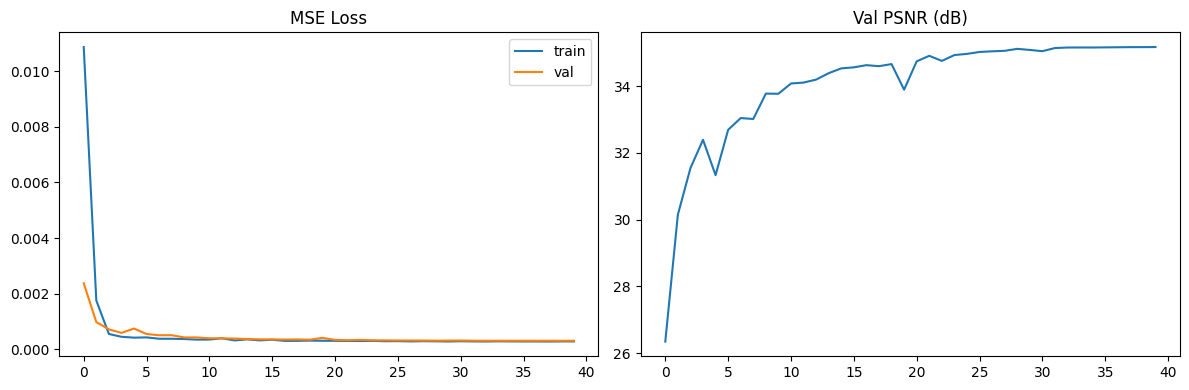

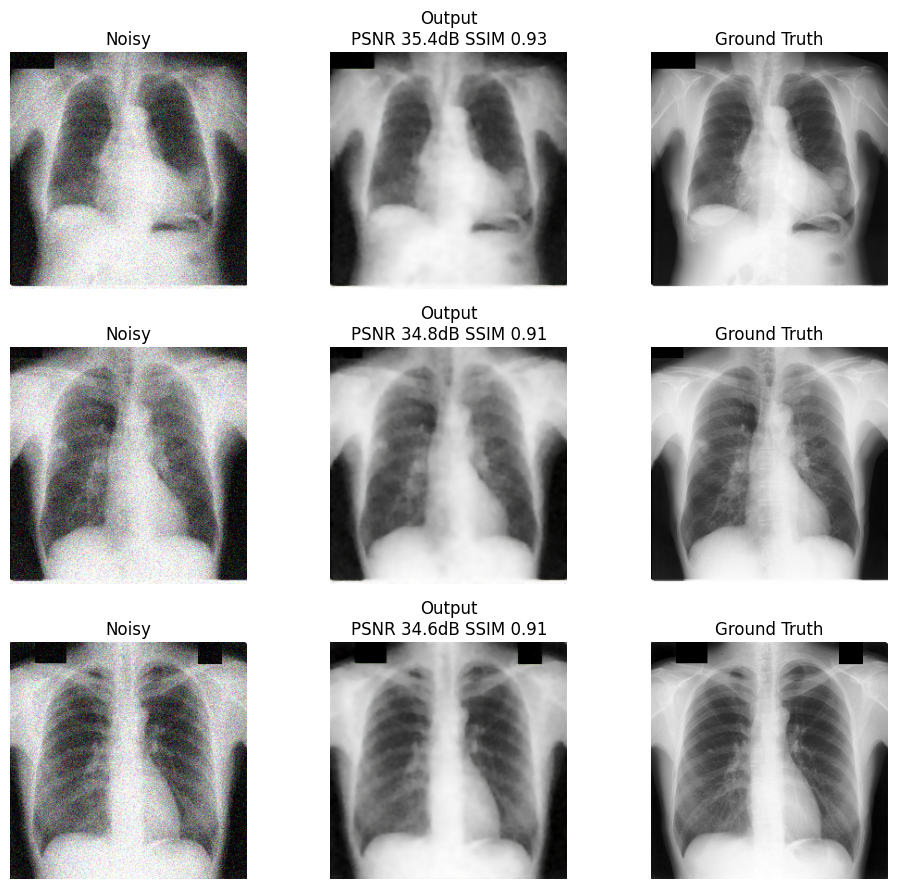

In [ ]:
# Cell 7: Evaluation
model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
model.eval()
print("Loaded best checkpoint from", CKPT_PATH)

psnrs, ssims, samples = [], [], []
with torch.no_grad():
    for i, (noisy, clean) in enumerate(val_loader):
        noisy, clean = noisy.to(device), clean.to(device)
        out = model(noisy).clamp(0, 1)

        out_np = out.squeeze(0).permute(1,2,0).cpu().numpy()
        clean_np = clean.squeeze(0).permute(1,2,0).cpu().numpy()
        psnrs.append(sk_psnr(clean_np, out_np, data_range=1.0))
        ssims.append(sk_ssim(clean_np, out_np, channel_axis=-1, data_range=1.0))

        if i < 3:
            noisy_np = noisy.squeeze(0).permute(1,2,0).cpu().numpy()
            samples.append((noisy_np, out_np, clean_np, psnrs[-1], ssims[-1]))

print(f"\nVal PSNR: {np.mean(psnrs):.3f} +/- {np.std(psnrs):.3f} dB")
print(f"Val SSIM: {np.mean(ssims):.4f} +/- {np.std(ssims):.4f}")
print("Paper reference (X-ray): PSNR 31.338 +/- 0.619, SSIM 0.888 +/- 0.014")

# Loss/PSNR curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(train_losses, label="train"); ax[0].plot(val_losses, label="val")
ax[0].set_title("MSE Loss"); ax[0].legend()
ax[1].plot(val_psnrs); ax[1].set_title("Val PSNR (dB)")
plt.tight_layout(); plt.show()

# Sample reconstructions
fig, axes = plt.subplots(len(samples), 3, figsize=(10, 3*len(samples)))
for r, (n, o, c, p, s) in enumerate(samples):
    axes[r,0].imshow(n); axes[r,0].set_title("Noisy"); axes[r,0].axis("off")
    axes[r,1].imshow(o); axes[r,1].set_title(f"Output\nPSNR {p:.1f}dB SSIM {s:.2f}"); axes[r,1].axis("off")
    axes[r,2].imshow(c); axes[r,2].set_title("Ground Truth"); axes[r,2].axis("off")
plt.tight_layout(); plt.show()
